# CHSH Violations using Dynamic Circuits

Simulation of **Waring, Pere & Le Beux (2025)**, *"CHSH Violations using Dynamic Circuits"* (arXiv:2504.18429).

We create an entangled Bell pair between the first and last qubit of a line of `d` qubits using three methods, then measure the CHSH score

$$S(\phi) = \langle ZZ\rangle_\phi - \langle ZX\rangle_\phi + \langle XZ\rangle_\phi + \langle XX\rangle_\phi$$

to see how well the entanglement survives as distance grows (classical limit $|S| \le 2$, quantum limit $|S| \le 2\sqrt{2} \approx 2.83$):

1. **Unitary**: moves qubit 0 down the line with SWAP gates, applies CNOT, and SWAPs back.
2. **Dynamic**: entangles the chain, measures the middle qubits, and applies a Z correction on the last qubit if needed.
3. **Post-processing**: same circuit as Dynamic without the Z correction; keeps only the runs where no correction was needed.

All circuits run on Qiskit's `AerSimulator` using the `FakeQuebec` noise model (a software model of IBM's 127-qubit `ibm_quebec` chip).

In [ ]:
!pip install qiskit qiskit-aer qiskit-ibm-runtime matplotlib numpy --quiet

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.


## Setup

In [ ]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit import Parameter
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeQuebec

warnings.filterwarnings('ignore')

fake_backend = FakeQuebec()
noise_model = NoiseModel.from_backend(fake_backend)
simulator = AerSimulator(noise_model=noise_model)
simulator.set_options(max_parallel_experiments=0, seed_simulator=1234)

PHI_VALUES = np.linspace(-np.pi / 2, 3 * np.pi, 21)
SHOTS = 2048
DISTANCES = [2, 3, 4, 5, 6, 7, 8]
BASES = ['ZZ', 'ZX', 'XZ', 'XX']
METHODS = ['unitary', 'dynamic', 'postprocess']
MIN_KEPT_SHOTS = 20

PHI = Parameter('phi')
print('Setup complete.')

Setup complete.


## CHSH Helpers

In [ ]:
def get_exp(counts, shots):
    """Return correlation <AB> in [-1, +1] from Qiskit measurement counts."""
    same = 0
    for bitstring, cnt in counts.items():
        pair = bitstring.split(' ')[0]
        if len(pair) >= 2 and pair[-1] == pair[-2]:
            same += cnt
    return (2 * same - shots) / shots if shots > 0 else 0.0

def compute_S(exp):
    return exp['ZZ'] - exp['ZX'] + exp['XZ'] + exp['XX']

## Method 1 — Unitary (SWAP-based)

In [ ]:
def build_unitary(distance, basis, phi):
    qr = QuantumRegister(distance, 'q')
    cr = ClassicalRegister(2, 'c')
    qc = QuantumCircuit(qr, cr)

    qc.h(qr[0])
    for i in range(distance - 2):
        qc.swap(qr[i], qr[i + 1])
    qc.cx(qr[distance - 2], qr[distance - 1])
    for i in range(distance - 3, -1, -1):
        qc.swap(qr[i], qr[i + 1])

    qc.ry(phi, qr[0])
    if basis[0] == 'X':
        qc.h(qr[0])
    if basis[1] == 'X':
        qc.h(qr[distance - 1])
    qc.measure(qr[0], cr[0])
    qc.measure(qr[distance - 1], cr[1])
    return qc

print(build_unitary(3, 'ZZ', 0).draw())

     ┌───┐           ┌───────┐┌─┐
q_0: ┤ H ├─X───────X─┤ Ry(0) ├┤M├
     └───┘ │       │ └───────┘└╥┘
q_1: ──────X───■───X───────────╫─
             ┌─┴─┐┌─┐          ║ 
q_2: ────────┤ X ├┤M├──────────╫─
             └───┘└╥┘          ║ 
c: 2/══════════════╩═══════════╩═
                   1           0 


## Method 2 — Dynamic (Mid-circuit Measurements + Feedforward)

In [ ]:
def build_dynamic(distance, basis, phi):
    n_relay = distance - 2
    qr = QuantumRegister(distance, 'q')
    cr = ClassicalRegister(2, 'c')

    if n_relay > 0:
        relay_bits = ClassicalRegister(n_relay, 'r')
        qc = QuantumCircuit(qr, relay_bits, cr)
    else:
        qc = QuantumCircuit(qr, cr)

    # Entangle the whole chain
    qc.h(qr[0])
    for k in range(distance - 1):
        qc.cx(qr[k], qr[k + 1])

    # Measure middle qubits in X basis and apply Z fix on the last qubit if needed
    for k in range(n_relay):
        qc.h(qr[k + 1])
        qc.measure(qr[k + 1], relay_bits[k])
    for k in range(n_relay):
        with qc.if_test((relay_bits[k], 1)):
            qc.z(qr[distance - 1])

    qc.ry(phi, qr[0])
    if basis[0] == 'X':
        qc.h(qr[0])
    if basis[1] == 'X':
        qc.h(qr[distance - 1])
    qc.measure(qr[0], cr[0])
    qc.measure(qr[distance - 1], cr[1])
    return qc

print(build_dynamic(3, 'ZZ', 0).draw())

     ┌───┐     ┌───────┐     ┌─┐                                
q_0: ┤ H ├──■──┤ Ry(0) ├─────┤M├────────────────────────────────
     └───┘┌─┴─┐└───────┘┌───┐└╥┘┌─┐                             
q_1: ─────┤ X ├────■────┤ H ├─╫─┤M├─────────────────────────────
          └───┘  ┌─┴─┐  └───┘ ║ └╥┘  ┌──────  ┌───┐ ───────┐ ┌─┐
q_2: ────────────┤ X ├────────╫──╫───┤ If-0  ─┤ Z ├  End-0 ├─┤M├
                 └───┘        ║  ║   └──╥───  └───┘ ───────┘ └╥┘
                              ║  ║ ┌────╨────┐                ║ 
r: 1/═════════════════════════╬══╩═╡ r_0=0x1 ╞════════════════╬═
                              ║  0 └─────────┘                ║ 
c: 2/═════════════════════════╩═══════════════════════════════╩═
                              0                               1 


## Method 3 — Post-Processing

In [ ]:
def build_postprocess(distance, basis, phi):
    n_relay = distance - 2
    qr = QuantumRegister(distance, 'q')
    cr = ClassicalRegister(2, 'c')

    if n_relay > 0:
        relay_bits = ClassicalRegister(n_relay, 'r')
        qc = QuantumCircuit(qr, relay_bits, cr)
    else:
        qc = QuantumCircuit(qr, cr)

    qc.h(qr[0])
    for k in range(distance - 1):
        qc.cx(qr[k], qr[k + 1])

    for k in range(n_relay):
        qc.h(qr[k + 1])
        qc.measure(qr[k + 1], relay_bits[k])

    qc.ry(phi, qr[0])
    if basis[0] == 'X':
        qc.h(qr[0])
    if basis[1] == 'X':
        qc.h(qr[distance - 1])
    qc.measure(qr[0], cr[0])
    qc.measure(qr[distance - 1], cr[1])
    return qc

def filter_pp(counts, n_relay):
    """Keep only shots where the XOR of all relay bits is 0 (no fix needed)."""
    if n_relay == 0:
        return counts, sum(counts.values())
    kept, total = {}, 0
    for bitstring, cnt in counts.items():
        parts = bitstring.split(' ')
        relay_part = parts[1] if len(parts) > 1 else ''
        xor_val = 0
        for bit in relay_part:
            xor_val ^= int(bit)
        if xor_val == 0:
            kept[parts[0]] = kept.get(parts[0], 0) + cnt
            total += cnt
    return kept, total

print(build_postprocess(3, 'ZZ', 0).draw())

     ┌───┐     ┌───────┐     ┌─┐   
q_0: ┤ H ├──■──┤ Ry(0) ├─────┤M├───
     └───┘┌─┴─┐└───────┘┌───┐└╥┘┌─┐
q_1: ─────┤ X ├────■────┤ H ├─╫─┤M├
          └───┘  ┌─┴─┐  └┬─┬┘ ║ └╥┘
q_2: ────────────┤ X ├───┤M├──╫──╫─
                 └───┘   └╥┘  ║  ║ 
r: 1/═════════════════════╬═══╬══╩═
                          ║   ║  0 
c: 2/═════════════════════╩═══╩════
                          1   0    


## Run Simulation

We build 84 circuit templates (3 methods × 7 distances × 4 bases) with a symbolic phase `phi`, transpile them together once, plug in the 21 phase values, and run all 1,764 circuits in one batch.

In [ ]:
builders = {
    'unitary': lambda d, b: build_unitary(d, b, PHI),
    'dynamic': lambda d, b: build_dynamic(d, b, PHI),
    'postprocess': lambda d, b: build_postprocess(d, b, PHI),
}
keys = [(m, d, b) for m in METHODS for d in DISTANCES for b in BASES]
templates = [builders[m](d, b) for (m, d, b) in keys]

t0 = time.perf_counter()
t_templates = transpile(templates, backend=fake_backend, optimization_level=1, seed_transpiler=42)
t1 = time.perf_counter()

circuits, index = [], []
for key, tqc in zip(keys, t_templates):
    for k, phi in enumerate(PHI_VALUES):
        circuits.append(tqc.assign_parameters({PHI: float(phi)}))
        index.append((*key, k))

result = simulator.run(circuits, shots=SHOTS).result()
t2 = time.perf_counter()
all_counts = {idx: result.get_counts(i) for i, idx in enumerate(index)}

print(f'Transpiled {len(templates)} templates in {t1 - t0:.1f} s')
print(f'Simulated {len(circuits)} circuits in {t2 - t1:.1f} s')

Transpiled 84 templates in 0.7 s
Simulated 1764 circuits in 174.3 s


### Compute S(phi) and max|S|

In [ ]:
E = {m: {d: {} for d in DISTANCES} for m in METHODS}
S_curves = {m: {} for m in METHODS}
results = {m: {} for m in METHODS}
pp_keep = {}

for m in METHODS:
    for d in DISTANCES:
        kept = []
        for b in BASES:
            vals = []
            for k in range(len(PHI_VALUES)):
                counts = all_counts[(m, d, b, k)]
                if m == 'postprocess':
                    fc, ft = filter_pp(counts, d - 2)
                    kept.append(ft / SHOTS)
                    vals.append(get_exp(fc, ft) if ft >= MIN_KEPT_SHOTS else 0.0)
                else:
                    vals.append(get_exp(counts, SHOTS))
            E[m][d][b] = np.array(vals)
        S_curves[m][d] = compute_S(E[m][d])
        results[m][d] = float(np.max(np.abs(S_curves[m][d])))
        if m == 'postprocess':
            pp_keep[d] = float(np.mean(kept))

def tag(v): return ' ✓' if v > 2 else '  '
print(f"{'Dist':>5} | {'Unitary':>9} | {'Dynamic':>9} | {'Post-Proc':>9} | {'PP kept':>7}")
print('-' * 56)
for d in DISTANCES:
    u, dy, pp = results['unitary'][d], results['dynamic'][d], results['postprocess'][d]
    print(f'{d:>5} | {u:>8.3f}{tag(u)} | {dy:>8.3f}{tag(dy)} | {pp:>8.3f}{tag(pp)} | {pp_keep[d]:>6.1%}')
print('✓ = CHSH violation (|S| > 2)')

 Dist |   Unitary |   Dynamic | Post-Proc | PP kept
--------------------------------------------------------
    2 |    2.566 ✓ |    2.537 ✓ |    2.531 ✓ | 100.0%
    3 |    2.221 ✓ |    2.404 ✓ |    2.431 ✓ |  50.2%
    4 |    1.984   |    2.367 ✓ |    2.319 ✓ |  50.0%
    5 |    1.841   |    2.286 ✓ |    2.293 ✓ |  50.1%
    6 |    1.643   |    2.104 ✓ |    2.104 ✓ |  50.1%
    7 |    1.528   |    1.993   |    1.992   |  49.9%
    8 |    1.272   |    1.878   |    1.991   |  49.9%
✓ = CHSH violation (|S| > 2)


## Results Graph — max|S| vs Qubit Distance

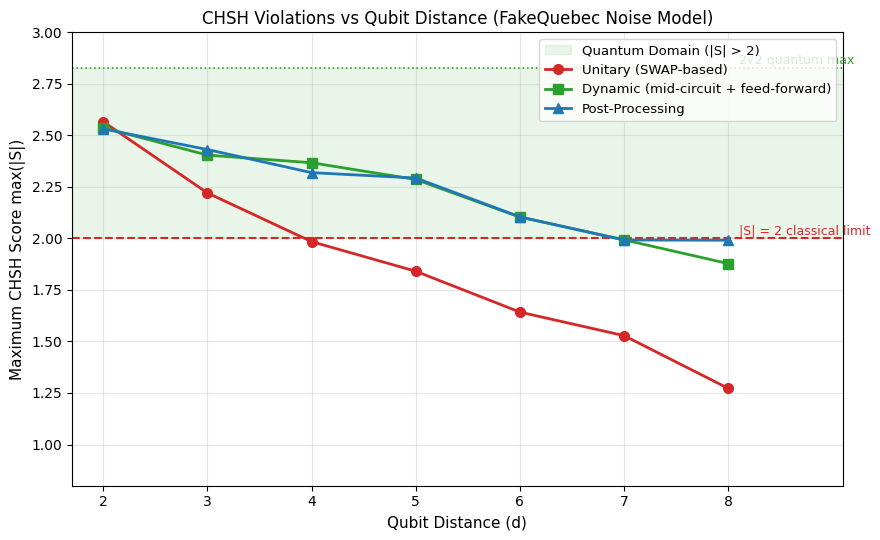

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5), facecolor='white')

d_vals = DISTANCES
Su = [results['unitary'][d] for d in d_vals]
Sd = [results['dynamic'][d] for d in d_vals]
Sp = [results['postprocess'][d] for d in d_vals]

ax.axhspan(2, 2 * np.sqrt(2), color='#2ca02c', alpha=0.10, label='Quantum Domain (|S| > 2)')
ax.axhline(2, color='#d62728', lw=1.5, linestyle='--')
ax.axhline(2 * np.sqrt(2), color='#2ca02c', lw=1.2, linestyle=':')
ax.text(d_vals[-1] + 0.1, 2.02, '|S| = 2 classical limit', color='#d62728', fontsize=9)
ax.text(d_vals[-1] + 0.1, 2 * np.sqrt(2) + 0.02, '2√2 quantum max', color='#2ca02c', fontsize=9)

ax.plot(d_vals, Su, 'o-', color='#d62728', lw=2, ms=7, label='Unitary (SWAP-based)')
ax.plot(d_vals, Sd, 's-', color='#2ca02c', lw=2, ms=7, label='Dynamic (mid-circuit + feed-forward)')
ax.plot(d_vals, Sp, '^-', color='#1f77b4', lw=2, ms=7, label='Post-Processing')

ax.set_xlabel('Qubit Distance (d)', fontsize=11)
ax.set_ylabel('Maximum CHSH Score max(|S|)', fontsize=11)
ax.set_title('CHSH Violations vs Qubit Distance (FakeQuebec Noise Model)', fontsize=12)
ax.set_xlim(d_vals[0] - 0.3, d_vals[-1] + 1.1)
ax.set_ylim(0.8, 3.0)
ax.set_xticks(d_vals)
ax.legend(fontsize=9.5, loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('chsh_results.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## S-Curves at d=3 and d=6
Re-uses `S_curves` from the batched run — **no circuits are re-built or re-simulated** here.

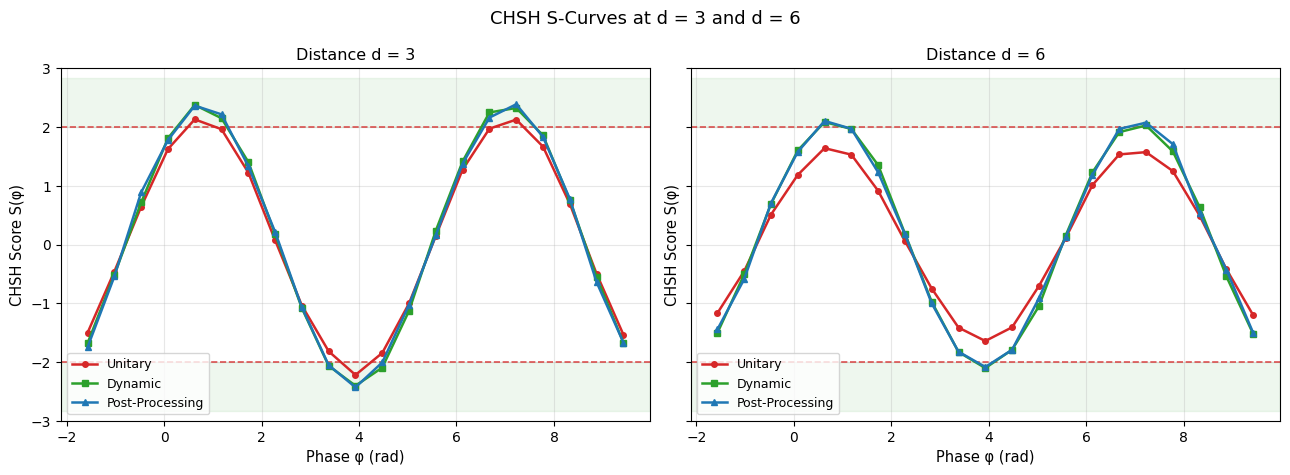

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True, facecolor='white')

for ax, d in zip(axes, [3, min(6, max(DISTANCES))]):
    ax.axhspan(2, 2 * np.sqrt(2), color='#2ca02c', alpha=0.08)
    ax.axhspan(-2 * np.sqrt(2), -2, color='#2ca02c', alpha=0.08)
    ax.axhline(2, color='#d62728', lw=1.2, linestyle='--', alpha=0.8)
    ax.axhline(-2, color='#d62728', lw=1.2, linestyle='--', alpha=0.8)

    ax.plot(PHI_VALUES, S_curves['unitary'][d], 'o-', color='#d62728', lw=1.8, ms=4, label='Unitary')
    ax.plot(PHI_VALUES, S_curves['dynamic'][d], 's-', color='#2ca02c', lw=1.8, ms=4, label='Dynamic')
    ax.plot(PHI_VALUES, S_curves['postprocess'][d], '^-', color='#1f77b4', lw=1.8, ms=4, label='Post-Processing')

    ax.set_title(f'Distance d = {d}', fontsize=11.5)
    ax.set_xlabel('Phase φ (rad)', fontsize=10.5)
    ax.set_ylabel('CHSH Score S(φ)', fontsize=10.5)
    ax.set_ylim(-3, 3)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('CHSH S-Curves at d = 3 and d = 6', fontsize=13)
plt.tight_layout()
plt.savefig('chsh_scurves.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## Extension 1: Transpiled 2-Qubit Gate Count & Depth
Compare the actual transpiled 2-qubit gate count (ECR) and circuit depth on `FakeQuebec` across distances.

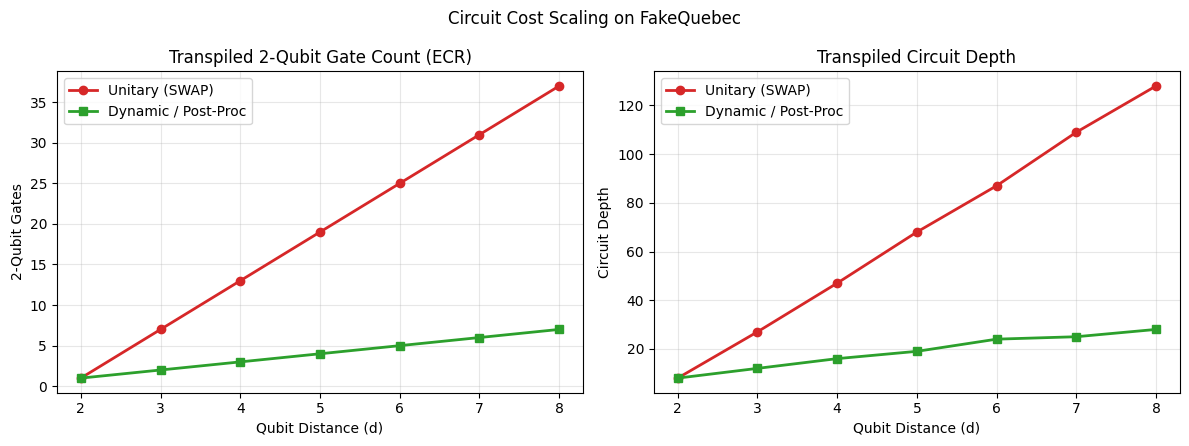

In [ ]:
twoq_counts = {'unitary': [], 'dynamic': []}
depths = {'unitary': [], 'dynamic': []}

for d in DISTANCES:
    for m, fn in [('unitary', build_unitary), ('dynamic', build_dynamic)]:
        tqc = transpile(fn(d, 'ZZ', 0.0), backend=fake_backend, optimization_level=1, seed_transpiler=42)
        ops = tqc.count_ops()
        twoq_counts[m].append(sum(v for k, v in ops.items() if k in ('ecr', 'cx', 'cz')))
        depths[m].append(tqc.depth())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), facecolor='white')
ax1.plot(DISTANCES, twoq_counts['unitary'], 'o-', color='#d62728', lw=2, label='Unitary (SWAP)')
ax1.plot(DISTANCES, twoq_counts['dynamic'], 's-', color='#2ca02c', lw=2, label='Dynamic / Post-Proc')
ax1.set_title('Transpiled 2-Qubit Gate Count (ECR)')
ax1.set_xlabel('Qubit Distance (d)')
ax1.set_ylabel('2-Qubit Gates')
ax1.set_xticks(DISTANCES)
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(DISTANCES, depths['unitary'], 'o-', color='#d62728', lw=2, label='Unitary (SWAP)')
ax2.plot(DISTANCES, depths['dynamic'], 's-', color='#2ca02c', lw=2, label='Dynamic / Post-Proc')
ax2.set_title('Transpiled Circuit Depth')
ax2.set_xlabel('Qubit Distance (d)')
ax2.set_ylabel('Circuit Depth')
ax2.set_xticks(DISTANCES)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('Circuit Cost Scaling on FakeQuebec')
plt.tight_layout()
plt.savefig('chsh_resources.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## Extension 2: Effect of Classical Feed-Forward Delay
Simulate idle decoherence during mid-circuit feed-forward using `FakeQuebec` median `T1` and `T2` times.

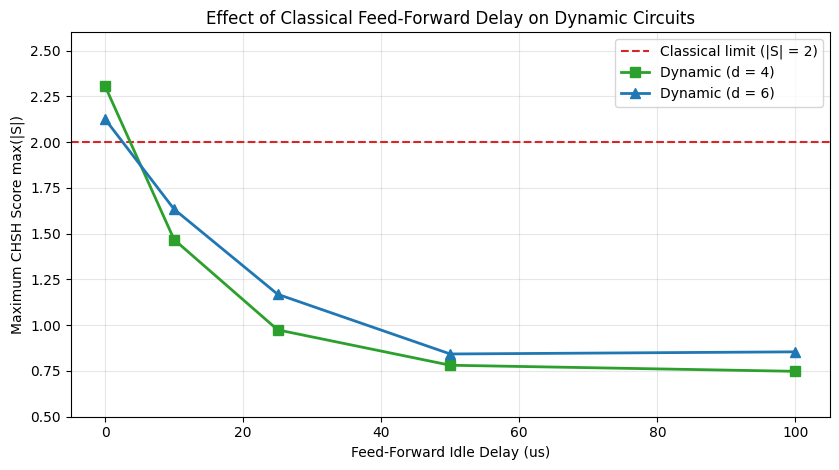

In [ ]:
from qiskit_aer.noise import thermal_relaxation_error

T1, T2 = 301.8e-6, 170.6e-6
DELAYS_US = [0, 10, 25, 50, 100]
DELAY_D = [4, 6]
delay_results = {d: [] for d in DELAY_D}

d_keys = [(d, b) for d in DELAY_D for b in BASES]
d_templates = transpile([build_dynamic(d, b, PHI) for (d, b) in d_keys],
                        backend=fake_backend, optimization_level=1, seed_transpiler=42)

def insert_delay(tqc, d, dl_us):
    layout = tqc.layout.final_index_layout()
    q_a, q_b = tqc.qubits[layout[0]], tqc.qubits[layout[d - 1]]
    out = QuantumCircuit(*tqc.qregs, *tqc.cregs)
    inserted = False
    for inst in tqc.data:
        if not inserted and inst.operation.name == 'if_else':
            out.delay(dl_us, q_a, unit='us')
            out.delay(dl_us, q_b, unit='us')
            inserted = True
        out.append(inst.operation, inst.qubits, inst.clbits)
    return out

for dl_us in DELAYS_US:
    nm = NoiseModel.from_backend(fake_backend)
    if dl_us > 0:
        nm.add_all_qubit_quantum_error(thermal_relaxation_error(T1, T2, dl_us * 1e-6), ['delay'])
    sim = AerSimulator(noise_model=nm)
    sim.set_options(max_parallel_experiments=0, seed_simulator=1234)

    circs, idx = [], []
    for (d, b), tqc in zip(d_keys, d_templates):
        c_wait = insert_delay(tqc, d, dl_us) if dl_us > 0 else tqc
        for k, phi in enumerate(PHI_VALUES):
            circs.append(c_wait.assign_parameters({PHI: float(phi)}))
            idx.append((d, b, k))

    res = sim.run(circs, shots=SHOTS).result()
    cmap = {i: res.get_counts(n) for n, i in enumerate(idx)}
    for d in DELAY_D:
        exp = {b: np.array([get_exp(cmap[(d, b, k)], SHOTS) for k in range(len(PHI_VALUES))]) for b in BASES}
        delay_results[d].append(float(np.max(np.abs(compute_S(exp)))))

fig, ax = plt.subplots(figsize=(8.5, 4.8), facecolor='white')
ax.axhline(2.0, color='#d62728', lw=1.5, linestyle='--', label='Classical limit (|S| = 2)')
ax.plot(DELAYS_US, delay_results[4], 's-', color='#2ca02c', lw=2, ms=7, label='Dynamic (d = 4)')
ax.plot(DELAYS_US, delay_results[6], '^-', color='#1f77b4', lw=2, ms=7, label='Dynamic (d = 6)')
ax.set_xlabel('Feed-Forward Idle Delay (us)')
ax.set_ylabel('Maximum CHSH Score max(|S|)')
ax.set_title('Effect of Classical Feed-Forward Delay on Dynamic Circuits')
ax.set_ylim(0.5, 2.6)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('chsh_delay.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## CHSH Concept Animation

Replays one full CHSH test in 4 steps using the simulated values from `unitary` at `d = 2`:
1. Create a Bell pair and send one qubit to Alice and one to Bob.
2. Alice and Bob each pick one of two measurement settings (`Z` or `X`).
3. Measure both qubits and record the average correlation `⟨AB⟩`.
4. Combine the four correlations into `S` and check if `|S| > 2`.

In [ ]:
from IPython.display import HTML
from matplotlib.patches import Circle, FancyBboxPatch

plt.rcParams['animation.embed_limit'] = 60

ANIM_METHOD, ANIM_D = 'unitary', DISTANCES[0]
k_best = int(np.argmax(S_curves[ANIM_METHOD][ANIM_D]))
phi_best = PHI_VALUES[k_best]
E_best = {b: float(E[ANIM_METHOD][ANIM_D][b][k_best]) for b in BASES}
S_best = float(S_curves[ANIM_METHOD][ANIM_D][k_best])

ROUNDS = [('ZZ', 'A₁', 'B₁', +1), ('ZX', 'A₁', 'B₂', -1),
          ('XZ', 'A₂', 'B₁', +1), ('XX', 'A₂', 'B₂', +1)]
SET_ANGLE = {'Z': 90.0, 'X': 0.0}

rng = np.random.default_rng(7)
SHOT = []
for basis, *_ in ROUNDS:
    a = int(rng.choice([+1, -1]))
    b = a if rng.random() < (1 + E_best[basis]) / 2 else -a
    SHOT.append((a, b))

INTERVAL_MS = 180
F_TRAVEL, F_CHOOSE, F_MEASURE = 12, 7, 9
F_ROUND = F_TRAVEL + F_CHOOSE + F_MEASURE
F_NEEDLE, F_HOLD = 14, 10
N_FRAMES = 4 * F_ROUND + F_NEEDLE + F_HOLD

def ease_in_out(t):
    t = min(max(t, 0.0), 1.0)
    return 4 * t**3 if t < 0.5 else 1 - (-2 * t + 2)**3 / 2

def ease_out(t):
    t = min(max(t, 0.0), 1.0)
    return 1 - (1 - t)**3

def timeline(f):
    if f < 4 * F_ROUND:
        r, lf = divmod(f, F_ROUND)
        if lf < F_TRAVEL:
            return r, 1, lf / (F_TRAVEL - 1)
        lf -= F_TRAVEL
        if lf < F_CHOOSE:
            return r, 2, lf / (F_CHOOSE - 1)
        lf -= F_CHOOSE
        return r, 3, lf / (F_MEASURE - 1)
    return 3, 4, (f - 4 * F_ROUND) / (F_NEEDLE - 1)

fig, ax = plt.subplots(figsize=(12, 7), dpi=80, facecolor='white')
ax.set_facecolor('white')
ax.set_xlim(0, 13)
ax.set_ylim(0, 7.5)
ax.axis('off')
fig.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.01)
fig.suptitle('How the CHSH Test Works', fontsize=15, fontweight='bold', color='#111')

STEP_NAMES = ['1. Send Bell pair', '2. Choose settings', '3. Measure & correlate', '4. Compute S']
STEP_COLORS = ['#d97706', '#7c3aed', '#2563eb', '#16a34a']
step_boxes, step_texts = [], []
for i, (name, col) in enumerate(zip(STEP_NAMES, STEP_COLORS)):
    x0 = 0.35 + i * 3.1
    box = FancyBboxPatch((x0, 6.6), 2.9, 0.55, boxstyle='round,pad=0.05',
                         facecolor='#f8fafc', edgecolor=col, lw=1.5)
    ax.add_patch(box)
    step_boxes.append(box)
    step_texts.append(ax.text(x0 + 1.45, 6.875, name, ha='center', va='center',
                              fontsize=10.5, fontweight='bold', color=col))

round_text = ax.text(6.5, 6.15, '', ha='center', fontsize=11, color='#333')

SRC = (6.5, 3.9)
src = Circle(SRC, 0.45, color='#f59e0b', zorder=5)
ax.add_patch(src)
ax.text(*SRC, 'Bell\nsource', ha='center', va='center', fontsize=8, fontweight='bold', color='#111', zorder=6)

def make_station(x0, name, col, face):
    ax.add_patch(FancyBboxPatch((x0, 2.65), 2.4, 2.55, boxstyle='round,pad=0.1',
                                facecolor=face, edgecolor=col, lw=2))
    ax.text(x0 + 1.2, 4.9, name, ha='center', fontsize=13, fontweight='bold', color=col)
    cx, cy = x0 + 1.2, 3.85
    ax.add_patch(Circle((cx, cy), 0.6, fill=False, edgecolor='#999', lw=1.2, zorder=3))
    dial, = ax.plot([], [], '-', color=col, lw=3, solid_capstyle='round', zorder=4)
    flash = Circle((cx, cy), 0.0, color=col, alpha=0.0, zorder=7)
    ax.add_patch(flash)
    setting = ax.text(cx, 3.0, '', ha='center', fontsize=11, fontweight='bold', color=col)
    outcome = ax.text(cx, 2.72, '', ha='center', fontsize=10, color='#111')
    return (cx, cy), dial, flash, setting, outcome

A_C, dial_A, flash_A, set_A, out_A = make_station(0.5, 'Alice', '#dc2626', '#fef2f2')
B_C, dial_B, flash_B, set_B, out_B = make_station(10.1, 'Bob', '#16a34a', '#f0fdf4')
A_EDGE, B_EDGE = 3.0, 10.0

trail_A, = ax.plot([], [], '-', color='#f59e0b', lw=2.5, alpha=0.8, zorder=4)
trail_B, = ax.plot([], [], '-', color='#f59e0b', lw=2.5, alpha=0.8, zorder=4)
dot_A = Circle(SRC, 0.13, color='#d97706', zorder=6)
dot_B = Circle(SRC, 0.13, color='#d97706', zorder=6)
ax.add_patch(dot_A)
ax.add_patch(dot_B)

main_text = ax.text(6.5, 5.55, '', ha='center', fontsize=12, fontweight='bold', color='#111')
detail_text = ax.text(6.5, 5.10, '', ha='center', fontsize=10.5, color='#444')

ax.add_patch(FancyBboxPatch((3.3, 1.75), 6.4, 0.95, boxstyle='round,pad=0.1',
                            facecolor='#f8fafc', edgecolor='#7c3aed', lw=1.5))
ax.text(6.5, 2.42, 'S = ⟨ZZ⟩ − ⟨ZX⟩ + ⟨XZ⟩ + ⟨XX⟩', ha='center', fontsize=11.5,
        fontweight='bold', color='#111')
tally_text = ax.text(6.5, 1.98, '', ha='center', fontsize=11, color='#1e293b', family='DejaVu Sans Mono')

M_X0, M_X1, M_Y = 3.4, 9.6, 0.85
def meter_x(s): return M_X0 + np.clip(s, 0, 3) / 3 * (M_X1 - M_X0)
ax.plot([M_X0, M_X1], [M_Y, M_Y], color='#cbd5e1', lw=6, solid_capstyle='round', zorder=2)
ax.plot([meter_x(2), meter_x(2 * np.sqrt(2))], [M_Y, M_Y], color='#16a34a', lw=6, alpha=0.35, zorder=2)
for val, lab, col in [(0, '0', '#666'), (1, '1', '#666'), (2, '2', '#dc2626'),
                      (2 * np.sqrt(2), '2√2', '#16a34a'), (3, '3', '#666')]:
    ax.plot([meter_x(val)] * 2, [M_Y - 0.17, M_Y + 0.17], color=col, lw=1.5, zorder=3)
    ax.text(meter_x(val), M_Y - 0.45, lab, ha='center', fontsize=9, color=col)
ax.text(M_X0 - 0.25, M_Y, '|S|', ha='right', va='center', fontsize=11, color='#111')
needle = Circle((M_X0, M_Y), 0.16, color='#dc2626', zorder=8)
ax.add_patch(needle)
S_label = ax.text(M_X0, M_Y + 0.32, '', ha='center', fontsize=10.5, fontweight='bold', color='#dc2626')

ax.add_patch(FancyBboxPatch((0.35, 0.35), 2.5, 1.0, boxstyle='round,pad=0.1',
                            facecolor='#fef2f2', edgecolor='#dc2626', lw=1.5))
ax.text(1.6, 1.0, 'Classical limit', ha='center', fontsize=9.5, color='#dc2626', fontweight='bold')
ax.text(1.6, 0.6, '|S| ≤ 2', ha='center', fontsize=11, color='#111')
ax.add_patch(FancyBboxPatch((10.15, 0.35), 2.5, 1.0, boxstyle='round,pad=0.1',
                            facecolor='#f0fdf4', edgecolor='#16a34a', lw=1.5))
ax.text(11.4, 1.0, 'Quantum limit', ha='center', fontsize=9.5, color='#16a34a', fontweight='bold')
ax.text(11.4, 0.6, '|S| ≤ 2√2 ≈ 2.83', ha='center', fontsize=11, color='#111')

def set_dial(line, centre, angle_deg, r=0.55):
    a = np.deg2rad(angle_deg)
    cx, cy = centre
    line.set_data([cx - r * np.cos(a), cx + r * np.cos(a)], [cy - r * np.sin(a), cy + r * np.sin(a)])

def angles_for(r):
    basis = ROUNDS[r][0]
    return SET_ANGLE[basis[0]] - np.rad2deg(phi_best), SET_ANGLE[basis[1]]

def tally_string(n_done):
    parts = []
    for i, (basis, _, _, sign) in enumerate(ROUNDS):
        val = f'({E_best[basis]:+.2f})' if i < n_done else '(  ?  )'
        op = '' if i == 0 else (' − ' if sign < 0 else ' + ')
        parts.append(op + val)
    return ''.join(parts)

def animate(frame):
    r, step, t = timeline(frame)
    basis, a_lab, b_lab, sign = ROUNDS[r]

    for i, (box, txt) in enumerate(zip(step_boxes, step_texts)):
        active = (i == step - 1)
        box.set_facecolor(STEP_COLORS[i] if active else '#f8fafc')
        box.set_alpha(1.0 if active else 0.55)
        txt.set_color('white' if active else STEP_COLORS[i])
        txt.set_alpha(1.0 if active else 0.55)
    round_text.set_text(f'Round {r + 1} / 4 · ({a_lab}, {b_lab}) → ⟨{basis}⟩'
                        if step < 4 else 'All four setting pairs measured')

    src.set_radius(0.45)
    flash_A.set_alpha(0)
    flash_B.set_alpha(0)
    prev_A, prev_B = angles_for(r - 1) if r > 0 else (90.0, 90.0)
    cur_A, cur_B = angles_for(r)
    if step in (2, 3):
        dot_A.center, dot_B.center = (A_EDGE, SRC[1]), (B_EDGE, SRC[1])
        dot_A.set_visible(True)
        dot_B.set_visible(True)
        trail_A.set_data([SRC[0], A_EDGE], [SRC[1]] * 2)
        trail_B.set_data([SRC[0], B_EDGE], [SRC[1]] * 2)
        set_A.set_text(f'{a_lab} = {basis[0]}')
        set_B.set_text(f'{b_lab} = {basis[1]}')

    if step == 1:
        e = ease_in_out(t)
        xa = SRC[0] - e * (SRC[0] - A_EDGE)
        xb = SRC[0] + e * (B_EDGE - SRC[0])
        dot_A.center, dot_B.center = (xa, SRC[1]), (xb, SRC[1])
        dot_A.set_visible(True)
        dot_B.set_visible(True)
        trail_A.set_data([SRC[0], xa], [SRC[1]] * 2)
        trail_B.set_data([SRC[0], xb], [SRC[1]] * 2)
        src.set_radius(0.45 + 0.08 * np.sin(np.pi * t))
        set_dial(dial_A, A_C, prev_A)
        set_dial(dial_B, B_C, prev_B)
        set_A.set_text('')
        set_B.set_text('')
        out_A.set_text('')
        out_B.set_text('')
        main_text.set_text('1. A Bell pair (|00⟩ + |11⟩)/√2 is sent to Alice and Bob')
        detail_text.set_text('H + CNOT on the first and last qubit')
    elif step == 2:
        e = ease_in_out(t)
        set_dial(dial_A, A_C, prev_A + e * (cur_A - prev_A))
        set_dial(dial_B, B_C, prev_B + e * (cur_B - prev_B))
        out_A.set_text('')
        out_B.set_text('')
        main_text.set_text(f'2. Alice chooses {a_lab} ({basis[0]}), Bob chooses {b_lab} ({basis[1]})')
        detail_text.set_text(f'Alice\'s qubit is rotated by Ry(φ), φ = {phi_best:.2f} rad')
    elif step == 3:
        e = ease_out(t)
        for fl in (flash_A, flash_B):
            fl.set_radius(0.15 + 0.75 * e)
            fl.set_alpha(0.45 * (1 - e))
        set_dial(dial_A, A_C, cur_A)
        set_dial(dial_B, B_C, cur_B)
        a, b = SHOT[r]
        if t >= 0.25:
            out_A.set_text(f'a = {a:+d}')
            out_B.set_text(f'b = {b:+d}')
            main_text.set_text(f'3. One shot: a = {a:+d}, b = {b:+d} → a·b = {a * b:+d}')
        else:
            main_text.set_text('3. Both qubits are measured...')
        detail_text.set_text(f'Averaged over {SHOTS} shots: ⟨{basis}⟩ = {E_best[basis]:+.3f}' if t >= 0.5 else '')
    else:
        dot_A.set_visible(False)
        dot_B.set_visible(False)
        trail_A.set_data([], [])
        trail_B.set_data([], [])
        set_dial(dial_A, A_C, cur_A)
        set_dial(dial_B, B_C, cur_B)
        out_A.set_text('')
        out_B.set_text('')
        set_A.set_text('')
        set_B.set_text('')
        verdict = 'violates' if abs(S_best) > 2 else 'does not violate'
        main_text.set_text(f'4. S = {S_best:+.3f} → {verdict} the classical limit |S| ≤ 2')
        detail_text.set_text(f'FakeQuebec simulation, {ANIM_METHOD} CNOT, distance {ANIM_D}')

    n_done = r + (1 if (step == 3 and t >= 0.5) else 0) if step < 4 else 4
    tally_text.set_text(tally_string(n_done))
    if step == 4:
        s_now = abs(S_best) * ease_in_out(t)
        col = '#16a34a' if s_now > 2 else '#dc2626'
        needle.center = (meter_x(s_now), M_Y)
        needle.set_color(col)
        S_label.set_position((meter_x(s_now), M_Y + 0.32))
        S_label.set_color(col)
        S_label.set_text(f'|S| = {s_now:.2f}')
    else:
        needle.center = (M_X0, M_Y)
        needle.set_color('#dc2626')
        S_label.set_text('')
    return []

ani = animation.FuncAnimation(fig, animate, frames=N_FRAMES, interval=INTERVAL_MS, blit=False, repeat=True)
plt.close(fig)
HTML(ani.to_jshtml(default_mode='loop'))

Output hidden; open in https://colab.research.google.com to view.